# 02 — What does upsampling leave behind? Simulation on Gaussian noise

**Goal:** understand the traces that an upsampling operation leaves in an image, in a
setting where we know the ground truth. We start from white Gaussian noise (no content,
no structure: every pixel independent), upsample it with different interpolation
kernels, and look at the result with the same tools as notebook 01 (high-pass +
autocorrelation), plus the power spectrum.

If Firefly's periodic signal comes from an upsampling step, one of these kernels should
reproduce the signatures seen in notebook 01 (period-2 zigzag in the autocorrelation,
bumps every 8 px, ...), or at least tell us which signatures upsampling *cannot* explain.

Kernels studied (all separable, i.e. applied along rows then columns):

| name | kernel | used by |
|---|---|---|
| nearest | box | nearest-neighbour / `ConvTranspose` with constant kernel |
| bilinear | triangle | most frameworks |
| bicubic a=-0.5 | Keys cubic | PIL, MATLAB |
| bicubic a=-0.75 | Keys cubic | OpenCV, PyTorch `interpolate` |
| lanczos2 / lanczos3 | windowed sinc | PIL (`LANCZOS` = lanczos3), image editors |

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from scipy.ndimage import gaussian_filter

from firefly_detection.config import RESULTS_DIR

rng = np.random.default_rng(0)

## 1. Upsampling, implemented explicitly

We implement interpolation ourselves rather than calling a library, so every choice is
visible. Conventions:

- **Pixel-center alignment** (`align_corners=False`, the default in PIL/OpenCV/PyTorch):
  output pixel $i$ samples the input at $x = (i + 0.5)/s - 0.5$ for factor $s$.
- **Periodic boundary** (wrap-around), so that borders introduce no artifacts and
  circular autocorrelation / FFT are exact.
- Weights are normalized to sum to 1 at every output pixel.

Each 1D resampling is a matrix $W$ (n_out × n_in), and the 2D upsampling is
$Y = W_y X W_x^T$.

In [2]:
def k_nearest(t):
    return ((t >= -0.5) & (t < 0.5)).astype(float)


def k_linear(t):
    return np.clip(1 - np.abs(t), 0, None)


def k_cubic(a):
    def k(t):
        t = np.abs(t)
        return np.where(
            t <= 1,
            (a + 2) * t**3 - (a + 3) * t**2 + 1,
            np.where(t < 2, a * t**3 - 5 * a * t**2 + 8 * a * t - 4 * a, 0.0),
        )
    return k


def k_lanczos(n):
    def k(t):
        return np.where(np.abs(t) < n, np.sinc(t) * np.sinc(t / n), 0.0)
    return k


KERNELS = {  # name -> (kernel, support radius in input pixels)
    "nearest": (k_nearest, 1),
    "bilinear": (k_linear, 1),
    "bicubic a=-0.5": (k_cubic(-0.5), 2),
    "bicubic a=-0.75": (k_cubic(-0.75), 2),
    "lanczos2": (k_lanczos(2), 2),
    "lanczos3": (k_lanczos(3), 3),
}


def resample_matrix(n_in, factor, kernel, support):
    """(n_out, n_in) interpolation matrix, pixel-center aligned, periodic boundary."""
    n_out = int(round(n_in * factor))
    x = (np.arange(n_out) + 0.5) / factor - 0.5          # source coordinate of each output pixel
    j = np.floor(x)[:, None] + np.arange(-support + 1, support + 1)  # neighbouring input pixels
    w = kernel(x[:, None] - j)
    w /= w.sum(axis=1, keepdims=True)
    W = np.zeros((n_out, n_in))
    np.add.at(W, (np.repeat(np.arange(n_out), j.shape[1]), j.astype(int).ravel() % n_in), w.ravel())
    return W


def upsample(x, factor, method):
    kernel, support = KERNELS[method]
    Wy = resample_matrix(x.shape[0], factor, kernel, support)
    Wx = resample_matrix(x.shape[1], factor, kernel, support)
    return Wy @ x @ Wx.T

### Sanity check against PIL

PIL's `resize` uses the same pixel-center convention, with `BICUBIC` = Keys a=-0.5 and
`LANCZOS` = lanczos3. Away from the borders (where PIL clamps instead of wrapping) the
two implementations should agree to floating-point precision.

In [3]:
x = rng.standard_normal((64, 64)).astype(np.float32)
pil_filters = {"nearest": Image.NEAREST, "bilinear": Image.BILINEAR,
               "bicubic a=-0.5": Image.BICUBIC, "lanczos3": Image.LANCZOS}
for name, f in pil_filters.items():
    ref = np.asarray(Image.fromarray(x, mode="F").resize((128, 128), f), dtype=np.float64)
    ours = upsample(x.astype(np.float64), 2, name)
    inner = (slice(8, -8), slice(8, -8))
    print(f"{name:16s} max |ours - PIL| (interior) = {np.abs(ours - ref)[inner].max():.2e}")

nearest          max |ours - PIL| (interior) = 0.00e+00
bilinear         max |ours - PIL| (interior) = 1.58e-07
bicubic a=-0.5   max |ours - PIL| (interior) = 2.02e-07
lanczos3         max |ours - PIL| (interior) = 2.11e-07


## 2. Upsampled noise, up close

Low-resolution white noise (512×512, σ = 1) upsampled ×2 to 1024×1024. Each panel shows
the same 32×32 corner, so the interpolation structure is visible pixel by pixel.

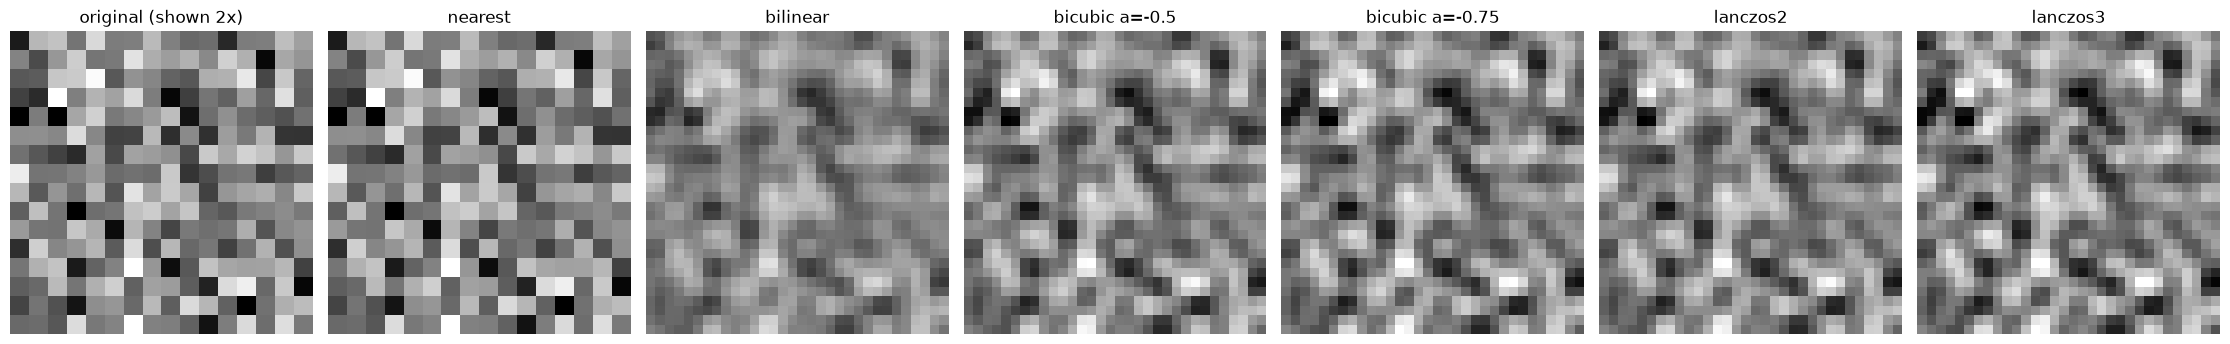

In [4]:
N_LOW, FACTOR = 512, 2
noise = rng.standard_normal((N_LOW, N_LOW))
up = {m: upsample(noise, FACTOR, m) for m in KERNELS}

fig, axes = plt.subplots(1, len(up) + 1, figsize=(3.2 * (len(up) + 1), 3.4))
axes[0].imshow(np.kron(noise[:16, :16], np.ones((2, 2))), cmap="gray", vmin=-2.5, vmax=2.5)
axes[0].set_title("original (shown 2x)")
for ax, (m, y) in zip(axes[1:], up.items()):
    ax.imshow(y[:32, :32], cmap="gray", vmin=-2.5, vmax=2.5)
    ax.set_title(m)
for ax in axes:
    ax.axis("off")
fig.tight_layout()

## 3. Power spectrum

White noise has a flat spectrum up to the low-resolution Nyquist frequency, 0.5 cycles
per *low-res* pixel = **0.25 cycles per output pixel**. Upsampling ×2 creates a spectral
**replica** of this band in [0.25, 0.5]; the interpolation kernel is a low-pass filter
that attenuates the replica, more or less well. What survives above 0.25 is the
upsampling fingerprint. The theoretical curve is $|\hat k(f)|^2$, the kernel's frequency
response.

Averaged over 16 noise realizations for a smooth estimate.

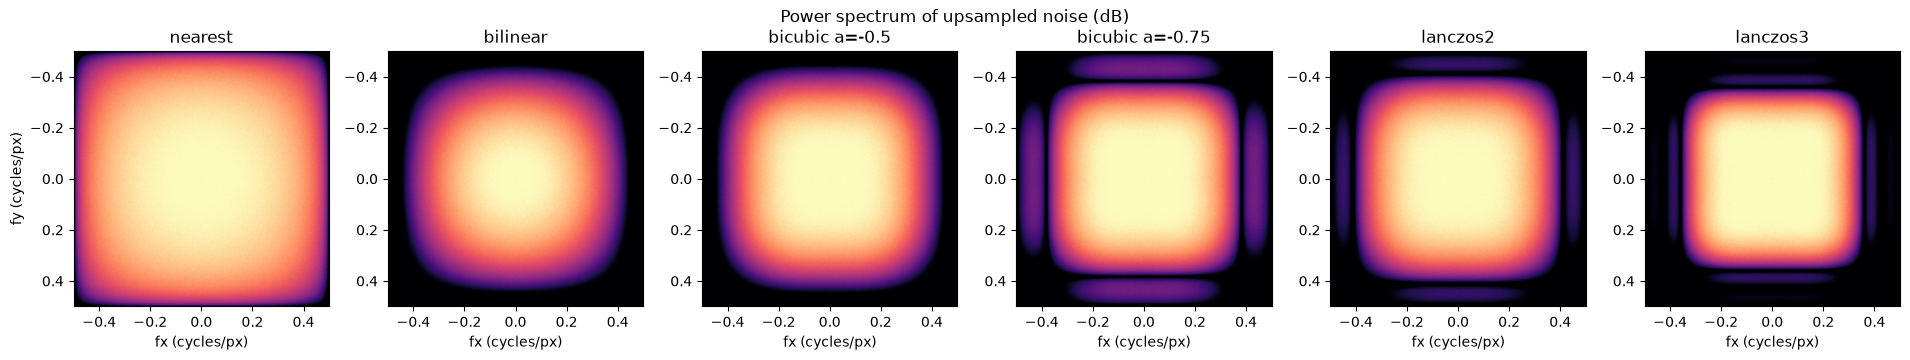

In [5]:
def power_spectrum(x):
    return np.fft.fftshift(np.abs(np.fft.fft2(x - x.mean())) ** 2) / x.size


N_REAL = 16
psd = {m: 0 for m in KERNELS}
for _ in range(N_REAL):
    z = rng.standard_normal((N_LOW, N_LOW))
    for m in KERNELS:
        psd[m] = psd[m] + power_spectrum(upsample(z, FACTOR, m)) / N_REAL

n = N_LOW * FACTOR
freqs = np.fft.fftshift(np.fft.fftfreq(n))

fig, axes = plt.subplots(1, len(psd), figsize=(3.2 * len(psd), 3.4))
for ax, (m, p) in zip(axes, psd.items()):
    ax.imshow(10 * np.log10(p + 1e-12), cmap="magma", vmin=-40, vmax=5,
              extent=(-0.5, 0.5, 0.5, -0.5))
    ax.set_title(m)
    ax.set_xlabel("fx (cycles/px)")
axes[0].set_ylabel("fy (cycles/px)")
fig.suptitle("Power spectrum of upsampled noise (dB)")
fig.tight_layout()

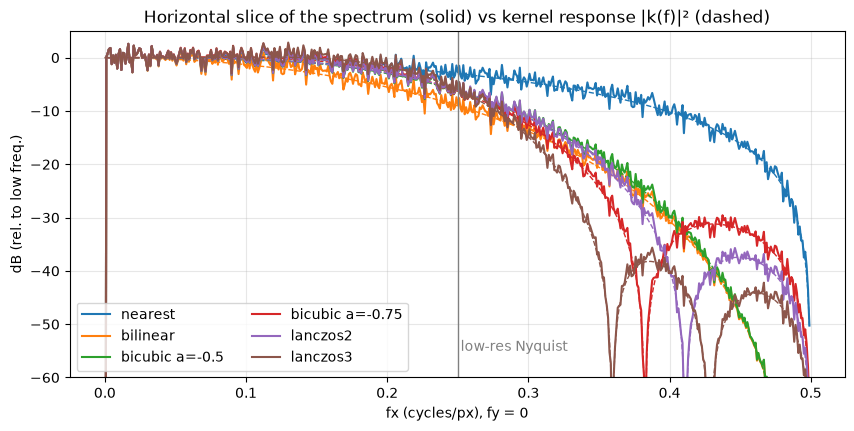

In [6]:
def kernel_response(kernel, support, factor, f):
    """|DTFT| of the equivalent filter on the output grid, normalized to 1 at f=0.

    Upsampling = zero-insertion followed by filtering with h[n] = k((n - (s-1)/2) / s):
    with pixel-center alignment the output pixels sit at offsets of (s-1)/2 output
    pixels from the input samples (±0.25 input px for s = 2).
    """
    t = (np.arange(-support * factor, support * factor + 1) - (factor - 1) / 2) / factor
    h = kernel(t)
    H = np.abs(np.exp(-2j * np.pi * np.outer(f, np.arange(len(h)))) @ h)
    return H / H[np.argmin(np.abs(f))]


pos = freqs >= 0
fig, ax = plt.subplots(figsize=(10, 4.5))
for m, p in psd.items():
    line, = ax.plot(freqs[pos], 10 * np.log10(p[n // 2, pos] / p[n // 2, n // 2 + 1]), lw=1.5, label=m)
    kernel, support = KERNELS[m]
    resp = kernel_response(kernel, support, FACTOR, freqs[pos])
    ax.plot(freqs[pos], 20 * np.log10(resp + 1e-12), lw=1, ls="--", color=line.get_color())
ax.axvline(0.25, color="gray", lw=1)
ax.text(0.252, -55, "low-res Nyquist", color="gray")
ax.set(xlabel="fx (cycles/px), fy = 0", ylabel="dB (rel. to low freq.)", ylim=(-60, 5),
       title="Horizontal slice of the spectrum (solid) vs kernel response |k(f)|² (dashed)")
ax.grid(alpha=0.3)
ax.legend(ncol=2)

## 4. Autocorrelation

Normalized circular autocorrelation (as in notebook 01), first of the raw upsampled
noise: it is the inverse Fourier transform of the spectrum above, so it shows the
*correlation introduced between neighbouring pixels* by the interpolation.

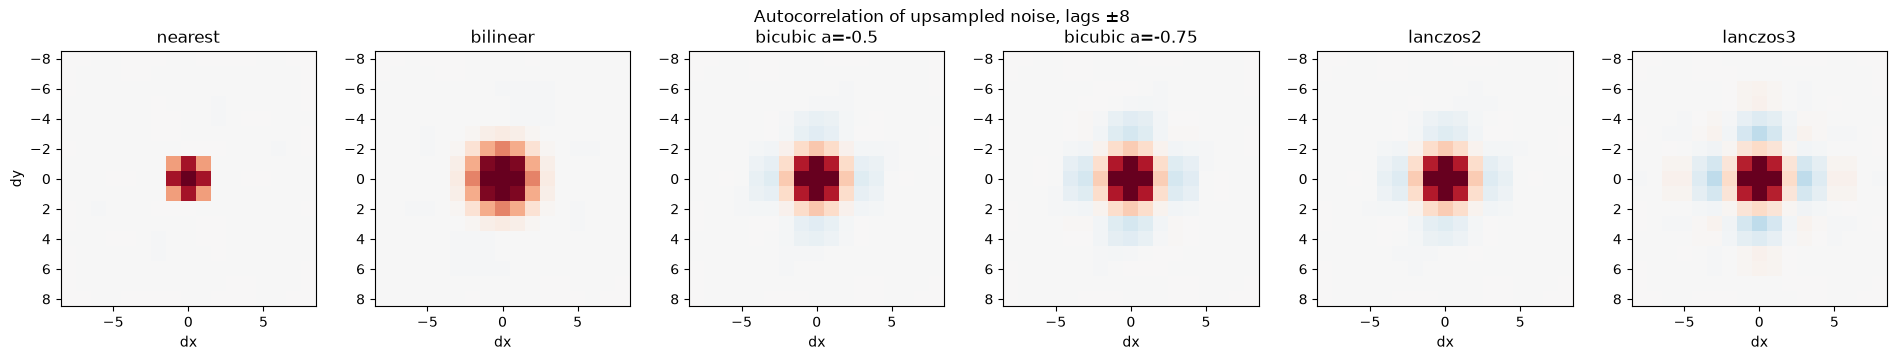

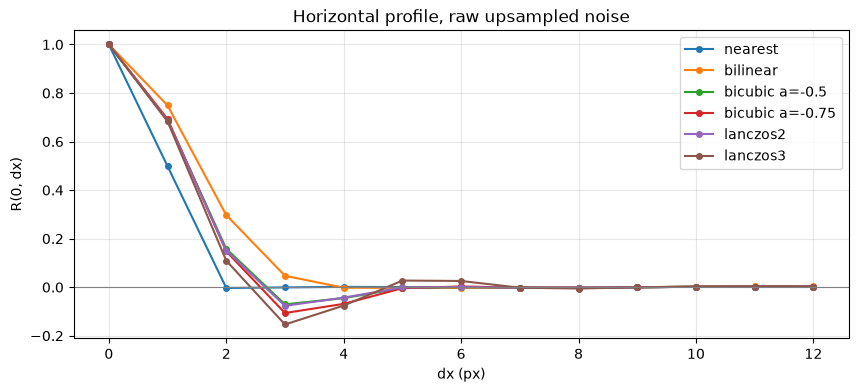

In [7]:
LAG = 32


def autocorrelation(x):
    x = x - x.mean()
    r = np.fft.ifft2(np.abs(np.fft.fft2(x)) ** 2).real
    return np.fft.fftshift(r / r.flat[0])


def crop_center(x, half):
    cy, cx = x.shape[0] // 2, x.shape[1] // 2
    return x[cy - half : cy + half + 1, cx - half : cx + half + 1]


acf = {m: crop_center(autocorrelation(y), LAG) for m, y in up.items()}
lags = np.arange(-LAG, LAG + 1)

fig, axes = plt.subplots(1, len(acf), figsize=(3.2 * len(acf), 3.4))
for ax, (m, r) in zip(axes, acf.items()):
    v = 0.6
    ax.imshow(crop_center(r, 8), cmap="RdBu_r", vmin=-v, vmax=v, extent=(-8.5, 8.5, 8.5, -8.5))
    ax.set_title(m)
    ax.set_xlabel("dx")
axes[0].set_ylabel("dy")
fig.suptitle("Autocorrelation of upsampled noise, lags ±8")
fig.tight_layout()

fig, ax = plt.subplots(figsize=(10, 4))
for m, r in acf.items():
    ax.plot(lags[LAG:LAG + 13], r[LAG, LAG:LAG + 13], marker="o", ms=4, lw=1.5, label=m)
ax.axhline(0, color="gray", lw=0.8)
ax.set(xlabel="dx (px)", ylabel="R(0, dx)", title="Horizontal profile, raw upsampled noise")
ax.grid(alpha=0.3)
ax.legend()

## 5. Same pipeline as notebook 01: high-pass, then autocorrelation

Notebook 01 high-passed the Firefly mean images with `x - gaussian_blur(x, σ=2)` before
the autocorrelation. Applying the exact same steps here lets us compare the profiles
directly with Firefly's (loaded from notebook 01's cached means; run it first).

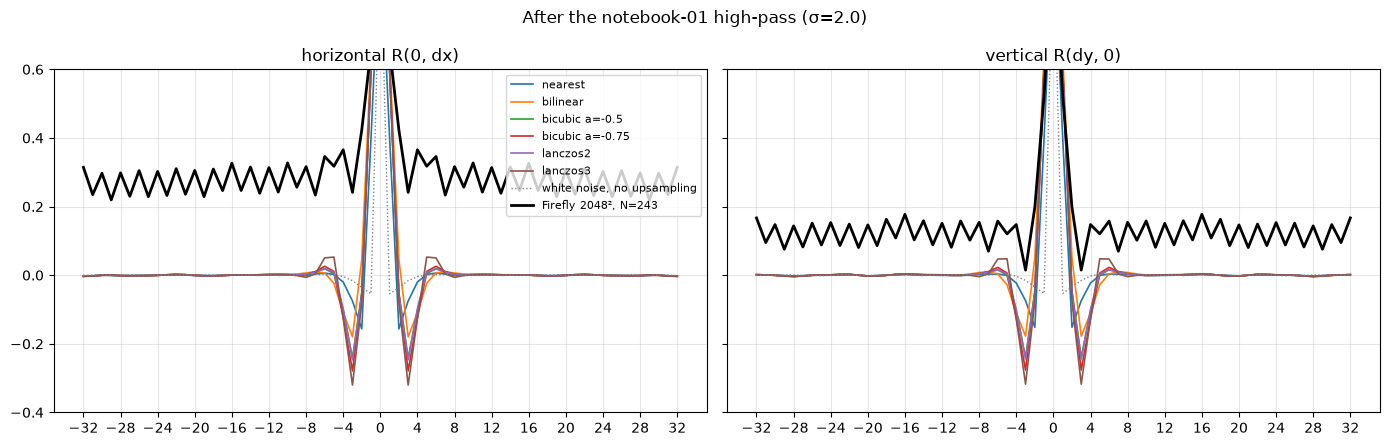

In [8]:
SIGMA = 2.0


def highpass(x, sigma=SIGMA):
    return x - gaussian_filter(x, sigma, mode="wrap")


acf_hp = {m: crop_center(autocorrelation(highpass(y)), LAG) for m, y in up.items()}

ff_file = RESULTS_DIR / "01_mean_autocorr" / "mean_2048x2048_n243.npy"
acf_ff = crop_center(autocorrelation(highpass(np.load(ff_file))), LAG) if ff_file.exists() else None
acf_white = crop_center(autocorrelation(highpass(rng.standard_normal((1024, 1024)))), LAG)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, (title, prof) in zip(axes, [("horizontal R(0, dx)", lambda r: r[LAG, :]),
                                    ("vertical R(dy, 0)", lambda r: r[:, LAG])]):
    for m, r in acf_hp.items():
        ax.plot(lags, prof(r), lw=1.2, label=m)
    ax.plot(lags, prof(acf_white), lw=1, color="gray", ls=":", label="white noise, no upsampling")
    if acf_ff is not None:
        ax.plot(lags, prof(acf_ff), lw=2, color="black", label="Firefly 2048², N=243")
    ax.set_title(title)
    ax.set_xticks(np.arange(-LAG, LAG + 1, 4))
    ax.set_ylim(-0.4, 0.6)
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
fig.suptitle(f"After the notebook-01 high-pass (σ={SIGMA})")
fig.tight_layout()

## 6. Periodic statistics: does the pixel's position modulo 2 matter?

Interpolation treats output pixels differently depending on where they fall relative to
the input grid: with ×2 pixel-center alignment, even and odd output pixels sit at
input offsets −0.25 and +0.25. If the kernel is not symmetric between these two
positions, or if a pixel coincides with an input sample, statistics like the variance
become **periodic with the upsampling factor** (cyclostationarity). This is the kind of
signal a detector can exploit even when the pattern changes from image to image.

We compute the variance of the high-passed upsampled image for each phase
$(y \bmod 2, x \bmod 2)$.

In [9]:
def phase_variance(x, period=2):
    return np.array([[x[i::period, j::period].var() for j in range(period)] for i in range(period)])


for m, y in up.items():
    v = phase_variance(highpass(y))
    print(f"{m:16s} variance by phase (rows: y mod 2, cols: x mod 2):  "
          f"{v[0,0]:.4f} {v[0,1]:.4f} | {v[1,0]:.4f} {v[1,1]:.4f}   ratio max/min = {v.max()/v.min():.3f}")

nearest          variance by phase (rows: y mod 2, cols: x mod 2):  0.7952 0.7953 | 0.7953 0.7952   ratio max/min = 1.000
bilinear         variance by phase (rows: y mod 2, cols: x mod 2):  0.2282 0.2282 | 0.2282 0.2282   ratio max/min = 1.000
bicubic a=-0.5   variance by phase (rows: y mod 2, cols: x mod 2):  0.4435 0.4435 | 0.4435 0.4435   ratio max/min = 1.000
bicubic a=-0.75  variance by phase (rows: y mod 2, cols: x mod 2):  0.4985 0.4985 | 0.4985 0.4985   ratio max/min = 1.000
lanczos2         variance by phase (rows: y mod 2, cols: x mod 2):  0.4541 0.4541 | 0.4541 0.4541   ratio max/min = 1.000
lanczos3         variance by phase (rows: y mod 2, cols: x mod 2):  0.5651 0.5651 | 0.5651 0.5651   ratio max/min = 1.000


With pixel-center alignment and a symmetric kernel the two phases are mirror images, so
the variances match. An **align-corners** convention (output pixel $i$ at
$x = i \cdot (n_{in}-1)/(n_{out}-1)$, or simply $x = i/s$) makes even output pixels
fall *exactly* on input samples: they are copies, while odd pixels are averages, with
lower variance. Let's check with $x = i/2$:

bilinear         variance by phase:  0.7910 0.3180 | 0.3199 0.0948   ratio max/min = 8.347
bicubic a=-0.5   variance by phase:  0.7764 0.4270 | 0.4291 0.2092   ratio max/min = 3.711
bicubic a=-0.75  variance by phase:  0.7691 0.4916 | 0.4939 0.2942   ratio max/min = 2.614
lanczos2         variance by phase:  0.7764 0.4270 | 0.4291 0.2092   ratio max/min = 3.711
lanczos3         variance by phase:  0.7665 0.5511 | 0.5529 0.3840   ratio max/min = 1.996


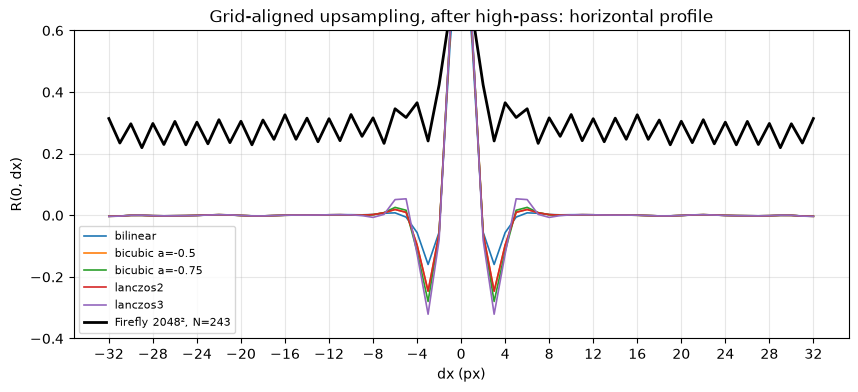

In [10]:
def upsample_on_grid(x, factor, method):
    """Like upsample(), but output pixel i samples the input at x = i / factor."""
    kernel, support = KERNELS[method]

    def mat(n_in):
        n_out = n_in * factor
        xs = np.arange(n_out) / factor
        j = np.floor(xs)[:, None] + np.arange(-support + 1, support + 1)
        w = kernel(xs[:, None] - j)
        w /= w.sum(axis=1, keepdims=True)
        W = np.zeros((n_out, n_in))
        np.add.at(W, (np.repeat(np.arange(n_out), j.shape[1]), j.astype(int).ravel() % n_in), w.ravel())
        return W

    return mat(x.shape[0]) @ x @ mat(x.shape[1]).T


up_grid = {m: upsample_on_grid(noise, FACTOR, m) for m in KERNELS if m != "nearest"}
for m, y in up_grid.items():
    v = phase_variance(highpass(y))
    print(f"{m:16s} variance by phase:  {v[0,0]:.4f} {v[0,1]:.4f} | {v[1,0]:.4f} {v[1,1]:.4f}"
          f"   ratio max/min = {v.max()/v.min():.3f}")

acf_grid = {m: crop_center(autocorrelation(highpass(y)), LAG) for m, y in up_grid.items()}
fig, ax = plt.subplots(figsize=(10, 4))
for m, r in acf_grid.items():
    ax.plot(lags, r[LAG, :], lw=1.2, label=m)
if acf_ff is not None:
    ax.plot(lags, acf_ff[LAG, :], lw=2, color="black", label="Firefly 2048², N=243")
ax.set(xlabel="dx (px)", ylabel="R(0, dx)", ylim=(-0.4, 0.6),
       title="Grid-aligned upsampling, after high-pass: horizontal profile")
ax.set_xticks(np.arange(-LAG, LAG + 1, 4))
ax.grid(alpha=0.3)
ax.legend(fontsize=8)

## Observations

_To fill in after looking at the figures._

Ideas for next steps:
- other factors (×4, ×8, non-integer), and cascaded ×2 stages;
- learned upsampling (transposed convolution, pixel shuffle) as used in diffusion decoders;
- JPEG compression after upsampling, to test robustness.